# NDVI de MODIS para un departamento y una campaña

Tarea 4 de la semana 2: NDVI promedio de MODIS para **un departamento** y **una campaña**, de punta a punta.

- **Departamento:** General López (Santa Fe), código INDEC `82042`.
- **Campaña:** 2015/16 (Niño fuerte), comparada con 2022/23 (sequía, Niña) y 2023/24 (Niño fuerte).
- **Dato:** MOD13Q1 v6.1 (Terra, 250 m, compuestos de 16 días) desde Microsoft Planetary Computer. **No requiere cuenta.**
- **Máscara de cultivo:** ESA WorldCover 2021 (clase 40, *cropland*), para quedarse con lotes agrícolas y no promediar pastizales, montes o lagunas.

Corre en Colab o local. En Colab, primero: `!pip install pystac-client planetary-computer rasterio geopandas matplotlib`.
Al final hay un bloque con el equivalente en Earth Engine.

In [1]:
import io, json, urllib.request
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
import pystac_client, planetary_computer as pc, rasterio
from rasterio.features import geometry_mask
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.windows import from_bounds

DEPTO_ID = "82042"          # General López
CAMPANAS = {"2015/16 (Niño fuerte)": ("2015-09-01", "2016-04-30"),
            "2022/23 (Niña, sequía)": ("2022-09-01", "2023-04-30"),
            "2023/24 (Niño fuerte)": ("2023-09-01", "2024-04-30")}

## 1. Polígono del departamento (IGN, servicio WFS)

General López - 11570 km²


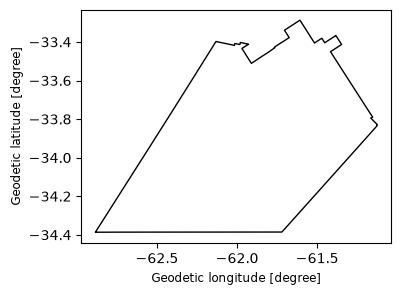

In [2]:
url = ("https://wms.ign.gob.ar/geoserver/ign/ows?service=WFS&version=1.0.0&request=GetFeature"
       f"&typeName=ign:departamento&outputFormat=application/json&CQL_FILTER=in1=%27{DEPTO_ID}%27")
depto = gpd.read_file(io.BytesIO(urllib.request.urlopen(url, timeout=120).read()))
print(depto.loc[0, "nam"], "-", round(depto.to_crs(32720).area.iloc[0] / 1e6), "km²")
depto.plot(edgecolor="k", facecolor="none", figsize=(4, 4));

## 2. Buscar los compuestos MOD13Q1 que tocan el departamento

In [3]:
cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)
bbox = list(depto.total_bounds)

def items_campana(desde, hasta):
    its = cat.search(collections=["modis-13Q1-061"], bbox=bbox, datetime=f"{desde}/{hasta}").items()
    return sorted([i for i in its if i.id.startswith("MOD13Q1")], key=lambda i: i.properties["start_datetime"])

items = {k: items_campana(*v) for k, v in CAMPANAS.items()}
{k: len(v) for k, v in items.items()}

{'2015/16 (Niño fuerte)': 16,
 '2022/23 (Niña, sequía)': 15,
 '2023/24 (Niño fuerte)': 16}

## 3. Grilla del departamento y máscara de cultivo

Se trabaja en la grilla sinusoidal nativa de MODIS (sin remuestrear). Se arma una ventana que cubre el
departamento, la máscara del polígono y la máscara de cultivo de WorldCover llevada a 250 m (moda).

In [4]:
ref = items["2015/16 (Niño fuerte)"][0]
assert all(i.id.split(".")[2] == ref.id.split(".")[2] for v in items.values() for i in v), "el depto cruza dos tiles"
with rasterio.open(ref.assets["250m_16_days_NDVI"].href) as src:
    crs = src.crs
    geom = depto.to_crs(crs).geometry.iloc[0]
    win = from_bounds(*geom.bounds, src.transform).round_offsets().round_lengths()
    tf = src.window_transform(win)
shape = (int(win.height), int(win.width))
dentro = ~geometry_mask([geom], out_shape=shape, transform=tf)

wc = next(cat.search(collections=["esa-worldcover"], bbox=bbox,
                     query={"esa_worldcover:product_version": {"eq": "2.0.0"}}).items())
with rasterio.open(wc.assets["map"].href) as wsrc, WarpedVRT(wsrc, crs=crs, transform=tf, width=shape[1],
                                                           height=shape[0], resampling=Resampling.mode) as vrt:
    cobertura = vrt.read(1)
cultivo = dentro & (cobertura == 40)
print(f"píxeles en el depto: {dentro.sum()}, de cultivo: {cultivo.sum()} ({cultivo.sum() / dentro.sum():.0%})")

píxeles en el depto: 215675, de cultivo: 169120 (78%)


## 4. NDVI medio por compuesto

Se usan solo píxeles con confiabilidad 0 (buena) o 1 (marginal); 2 = nieve, 3 = nube. El NDVI viene escalado ×10000.

In [5]:
def leer(item, banda):
    with rasterio.open(item.assets[banda].href) as src:
        return src.read(1, window=win)

filas = []
for campana, its in items.items():
    for it in its:
        ndvi = leer(it, "250m_16_days_NDVI") * 1e-4
        rel = leer(it, "250m_16_days_pixel_reliability")
        ok = cultivo & np.isin(rel, [0, 1])
        filas.append({"campana": campana, "fecha": pd.Timestamp(it.properties["start_datetime"][:10]),
                      "ndvi_cultivo": ndvi[ok].mean() if ok.any() else np.nan,
                      "pct_valido": ok.sum() / cultivo.sum() * 100})
ndvi = pd.DataFrame(filas)
ndvi.head()

,campana,fecha,ndvi_cultivo,pct_valido
0,2015/16 (Niño fuerte),2015-08-29,0.458301,97.590468
1,2015/16 (Niño fuerte),2015-09-14,0.446527,93.007923
2,2015/16 (Niño fuerte),2015-09-30,0.446525,95.333491
3,2015/16 (Niño fuerte),2015-10-16,0.437740,98.404683
4,2015/16 (Niño fuerte),2015-11-01,0.450318,99.820837


## 5. Curvas de la campaña

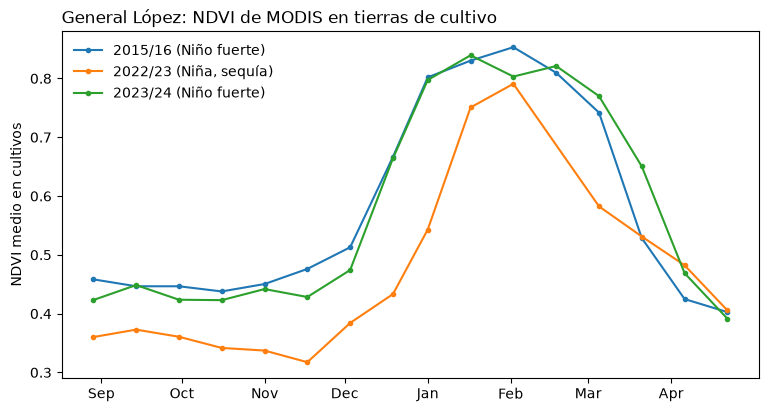

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for campana, g in ndvi.groupby("campana", sort=False):
    inicio = g["fecha"].min()
    dias = (g["fecha"] - pd.Timestamp(year=inicio.year, month=9, day=1)).dt.days
    ax.plot(dias, g["ndvi_cultivo"], marker="o", ms=3, label=campana)
ticks = pd.date_range("2015-09-01", "2016-04-30", freq="MS")
ax.set_xticks((ticks - ticks[0]).days, [t.strftime("%b") for t in ticks])
ax.set_ylabel("NDVI medio en cultivos"); ax.legend(frameon=False)
ax.set_title(f"General López: NDVI de MODIS en tierras de cultivo", loc="left")
plt.show()

In [7]:
# Resumen: pico y promedio de verano (dic-mar), que es lo que más se relaciona con el rinde
ndvi["mes"] = ndvi["fecha"].dt.month
resumen = ndvi.groupby("campana", sort=False).agg(
    ndvi_pico=("ndvi_cultivo", "max"),
    ndvi_dic_mar=("ndvi_cultivo", lambda s: s[ndvi.loc[s.index, "mes"].isin([12, 1, 2, 3])].mean()),
    compuestos=("ndvi_cultivo", "count"), pct_valido_min=("pct_valido", "min"))
resumen.round(3)

,ndvi_pico,ndvi_dic_mar,compuestos,pct_valido_min
campana,,,,
2015/16 (Niño fuerte),0.853,0.718,16,93.008
"2022/23 (Niña, sequía)",0.791,0.574,15,83.666
2023/24 (Niño fuerte),0.839,0.727,16,85.214


In [8]:
# Rinde oficial de esas campañas (MAGyP) para poner el NDVI en contexto
magyp = pd.read_csv("https://datos.magyp.gob.ar/dataset/9e1e77ba-267e-4eaa-a59f-3296e86b5f36/resource/"
                    "95d066e6-8a0f-4a80-b59d-6f28f88eacd5/download/estimaciones-agricolas-2026-03.csv",
                    dtype={"departamento_id": str})
r = magyp[(magyp.departamento_id == DEPTO_ID) & magyp.cultivo.isin(["soja total", "maíz"])
          & magyp.anio.isin([2015, 2022, 2023])]
r.pivot_table(index="campania", columns="cultivo", values="rendimiento_kgxha")

cultivo,maíz,soja total
campania,,
2015/2016,10300.0,3265.0
2022/2023,5700.0,1461.0
2023/2024,9400.0,3364.0


## Equivalente en Google Earth Engine

Mismo cálculo con la API de Python de Earth Engine (necesita cuenta y `ee.Authenticate()`).
**No se ejecutó en este notebook**: queda como guía para quien tome el frente satelital.

```python
import ee
ee.Initialize(project="TU-PROYECTO")
depto = (ee.FeatureCollection("FAO/GAUL/2015/level2")      # o subir el polígono del IGN como asset
         .filter(ee.Filter.eq("ADM2_NAME", "General Lopez")))
cultivo = ee.ImageCollection("ESA/WorldCover/v200").first().eq(40)
def ndvi_medio(img):
    ok = img.select("SummaryQA").lte(1)
    ndvi = img.select("NDVI").multiply(0.0001).updateMask(ok).updateMask(cultivo)
    v = ndvi.reduceRegion(ee.Reducer.mean(), depto.geometry(), 250, maxPixels=1e9)
    return ee.Feature(None, {"fecha": img.date().format("YYYY-MM-dd"), "ndvi": v.get("NDVI")})
serie = (ee.ImageCollection("MODIS/061/MOD13Q1").filterDate("2015-09-01", "2016-05-01")
         .map(ndvi_medio).getInfo())
```